In [2]:
!pip install pandas numpy matplotlib scikit-learn

You should consider upgrading via the 'C:\Users\LEGION 5\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt


<hr color=white>

### <font color='#ff1313'>**Problems in the Dataset**</font>

<strong>1. Original file dose not give DateTime column any name</strong><br>
<strong>2. Original file represent float as "14,5" instead of 14.5</strong><br>
<hr color=white>

### <font color="#33ff00">Fixing the problem :</font>

In [4]:
import os

file_path = os.path.join("data", r"C:\Users\LEGION 5\Desktop\choch you\data\LD2011_2014.txt")

print("Current folder:", os.getcwd())
print("File exists:", os.path.exists(file_path))
print("File path:", os.path.abspath(file_path))

Current folder: c:\Users\LEGION 5\Downloads
File exists: True
File path: C:\Users\LEGION 5\Desktop\choch you\data\LD2011_2014.txt


In [5]:

with open(file_path , "r") as file : # read the file 
    content = file.read()
    content = content.replace('""' , '"DateTime"') # Give `datetime` column name by replace the empty text with "DateTime"
    content = content.replace(',' , '.')           # Replace the comma with a point, so the Pandas parser could cast it to `float64`

with open(file_path , "w") as file :
    file.write(content)

del content

In [6]:
# Load the Dateset
df = pd.read_csv(file_path , delimiter=";")


#### **Note : `datetime` column is loaded as `object` type (`string`) , so it requires type casting.**

In [7]:
df['DateTime'] = pd.to_datetime(df['DateTime']) # change `DateTime` column type from `object` to `DateTime`
df = df.set_index('DateTime')                   # set datetime as the index


<hr color=white>
<hr color=white>

# $$Exploratory \space\space Data \space\space Analysis \space\space (EDA)$$


In [8]:
print("[+] Dataset Shape : ",df.shape)
print("[+] The Number of participating consumers since the start of recording : ",(df.loc[df.index[0]] > 0).sum())
print("[+] The Number of consumers who participated subsequently : ",(df.loc[df.index[0]] == 0).sum())

[+] Dataset Shape :  (140256, 370)
[+] The Number of participating consumers since the start of recording :  158
[+] The Number of consumers who participated subsequently :  212


In [9]:
df.iloc[:,[170]]

,MT_171
DateTime,
2011-01-01 00:15:00,137.885196
2011-01-01 00:30:00,150.030211
2011-01-01 00:45:00,153.051360
2011-01-01 01:00:00,156.102719
2011-01-01 01:15:00,146.978852
...,...
2014-12-31 23:00:00,137.885196
2014-12-31 23:15:00,134.864048
2014-12-31 23:30:00,125.770393


In [10]:
# Examples of some consumers at a period of time
df.iloc[110000:110010,100:107]

,MT_101,MT_102,MT_103,MT_104,MT_105,MT_106,MT_107
DateTime,,,,,,,
2014-02-19 20:15:00,763.066202,1109.643329,1671.186441,615.841584,302.300110,42.735043,22.484542
2014-02-19 20:30:00,797.909408,1085.865258,1603.389831,611.881188,237.130340,38.936372,28.667791
2014-02-19 20:45:00,785.714286,1060.766182,1583.050847,616.831683,208.105148,41.785375,26.419337
2014-02-19 21:00:00,768.292683,1031.704095,1593.220339,613.861386,201.533406,39.886040,22.484542
2014-02-19 21:15:00,763.066202,993.394980,1577.966102,608.910891,197.152245,37.986705,19.111861
2014-02-19 21:30:00,796.167247,993.394980,1559.322034,613.861386,199.342826,37.986705,19.673974
2014-02-19 21:45:00,752.613240,994.715984,1567.796610,608.910891,198.795181,39.886040,19.673974
2014-02-19 22:00:00,777.003484,841.479524,1525.423729,602.970297,189.485214,38.936372,19.111861
2014-02-19 22:15:00,729.965157,647.291942,1311.864407,469.306931,182.913472,34.188034,19.111861


<hr color=white>

# **Dataset Description**
- **This dataset contain 370 records for 370 consumers**
- **Each consumer represent a pattern of consumption in the dataset**
- **Each record consists of 140,256 time points, separated by 15-minute intervals.**
- **Recording start at 2011-1-1 and end at 2015-1-1**
- **Each point represent the consumption of the electricity at a specific moment in time for specific consumer in `KW` unit**
- **Some consumers participated after 2011, in these cases consumption were considered zero.**
<hr color=white>

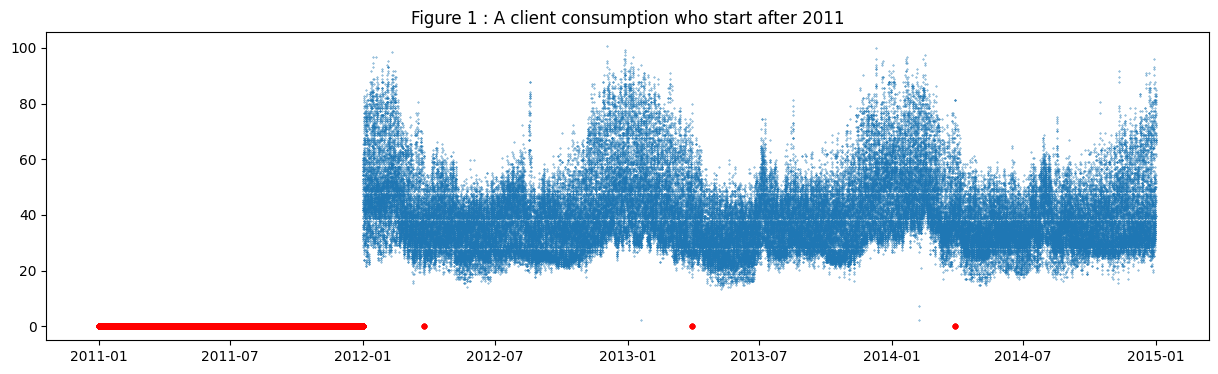

In [11]:
# Example of an client consumption who start at 2012
#----------------------------------------------------
n = 10
data = df.loc["2011-01-01 00:00:00":"2015-01-10 00:00:00"]
plt.figure(figsize=(15, 4) )
plt.title("Figure 1 : A client consumption who start after 2011")
plt.scatter(
    data.index,
    data.values[:,n],
    s=0.1)


zero_points = data.values[:,n] == 0
plt.scatter(
    data.index[zero_points],
    data.values[:,n][zero_points],
    color="red",
    s=10,
    label="Zeros",
)
plt.show()

In [12]:
print("[+] Number of Duplicated: ",df.duplicated().sum())

[+] Number of Duplicated:  0


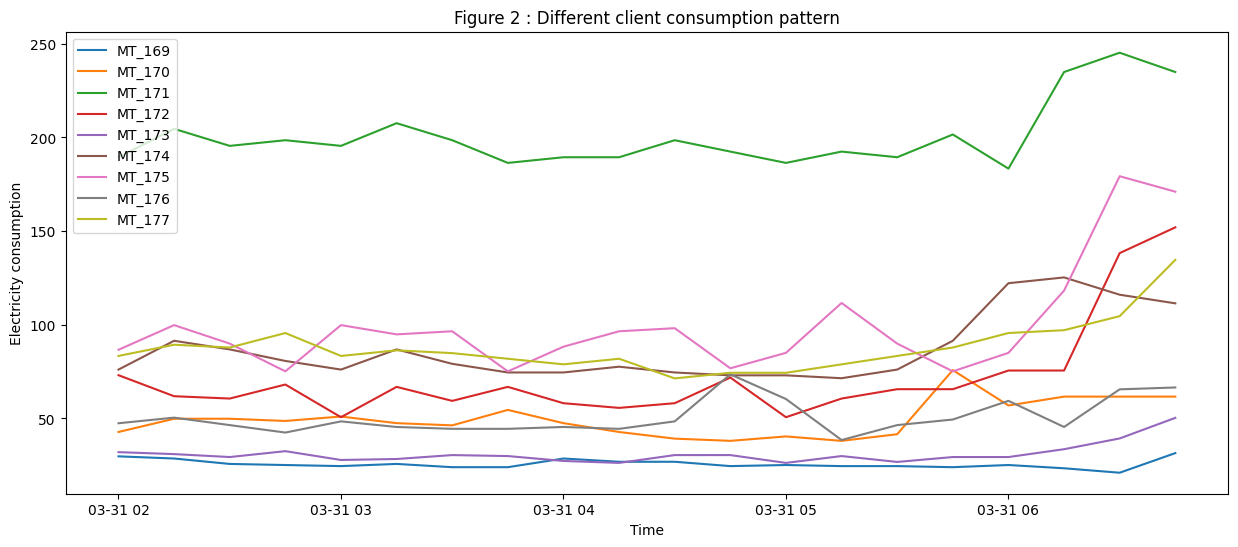

In [13]:
# Display some examples of client Electricity Consumption at a period of time
#-----------------------------------------------------------------------------
consumer_num = 168
series_len = 20
series_start = 113727-(35000*1)
data = df.iloc[series_start:series_start+series_len , consumer_num:consumer_num+9]

plt.figure(figsize=(15, 6))

for col in data.columns:
    plt.plot(data.index, data[col], label=col)

plt.title("Figure 2 : Different client consumption pattern")
plt.xlabel("Time")
plt.ylabel("Electricity consumption")
plt.legend()
plt.show()


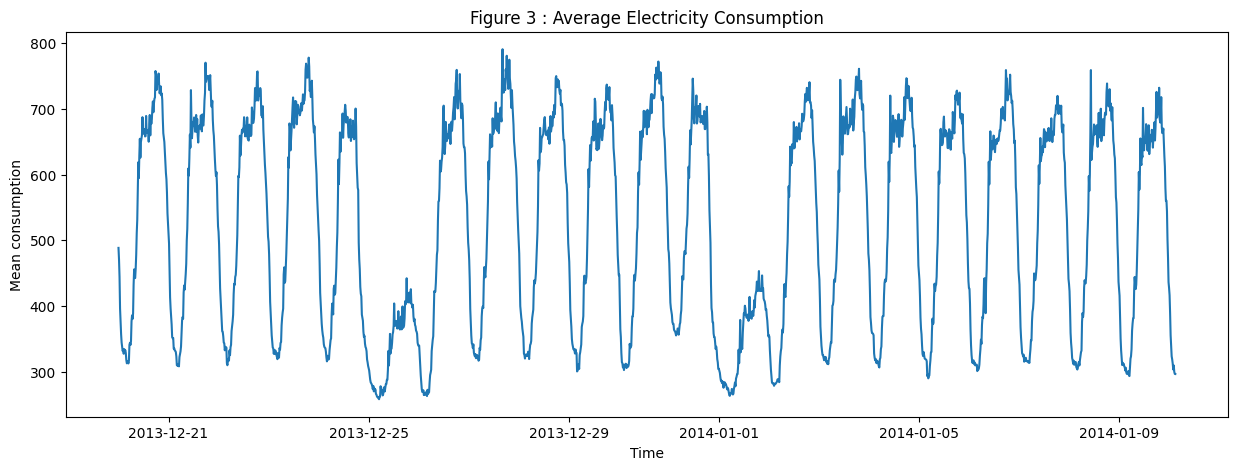

In [14]:
# Display the average Electricity consumption over all clients at a period of time
#----------------------------------------------------------------------------------
start = "2013-12-20 00:00:00" ; end = "2014-01-10 3:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 5))
plt.plot(mean_consumption.index, mean_consumption)
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 3 : Average Electricity Consumption")
plt.show()

<hr color=white>

### **NOTE:**
**1. On the daylight saving time (DST) transition day in March, which has only 23 hours, the values between 1:00 AM and 2:00 AM are reported as zero for all points.**<br>
**2. On the daylight saving time (DST) transition day in October, which has 25 hours, the values between 1:00 AM and 2:00 AM represent the aggregated consumption of two hours.**<br>

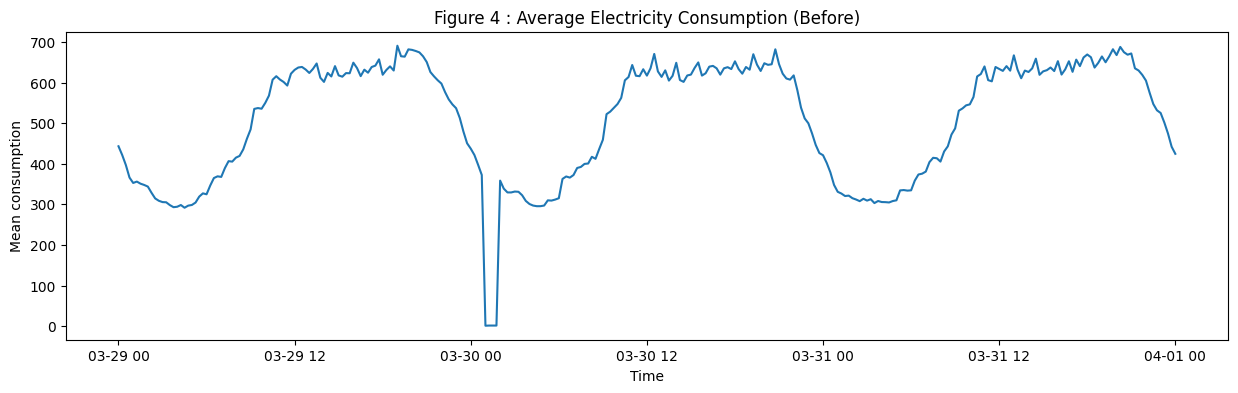

In [15]:
# Display the average consumption at DST Before handling the error
#------------------------------------------------------------------
start = "2014-03-29 00:00:00" ; end = "2014-04-01 0:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 4))
plt.plot(mean_consumption.index, mean_consumption)
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 4 : Average Electricity Consumption (Before)")
plt.show()


### **<font color="#33ff00">How It will Handled:</font>**

* **March:** Zero values caused by the DST transition were replaced with the average of the previous and next points.
* **October:** The aggregated values during the DST transition were also replaced with the average of the previous and next points.


In [16]:

march_dates   = [ '2014-03-30', '2013-03-31', '2012-03-25' ]
october_dates = [ '2014-10-26', '2013-10-27', '2012-10-28' ]
all_dates = march_dates + october_dates
columns = df.columns

for date in all_dates:        
    previous_time = pd.Timestamp(f'{date} 00:45:00')
    next_time     = pd.Timestamp(f'{date} 02:00:00')

    previous_value = df.loc[previous_time, columns] # Get Previous point
    next_value     = df.loc[next_time, columns]     # Get Next point


    estimated_value = (previous_value + next_value) / 2


    mask = ((df.index >= pd.Timestamp(f'{date} 01:00:00')) &
            (df.index <= pd.Timestamp(f'{date} 01:45:00'))   )  # Update only the values in specific interval

    n_rows = mask.sum()
    df.loc[mask, columns] = np.tile(estimated_value.to_numpy(),(n_rows, 1))
    


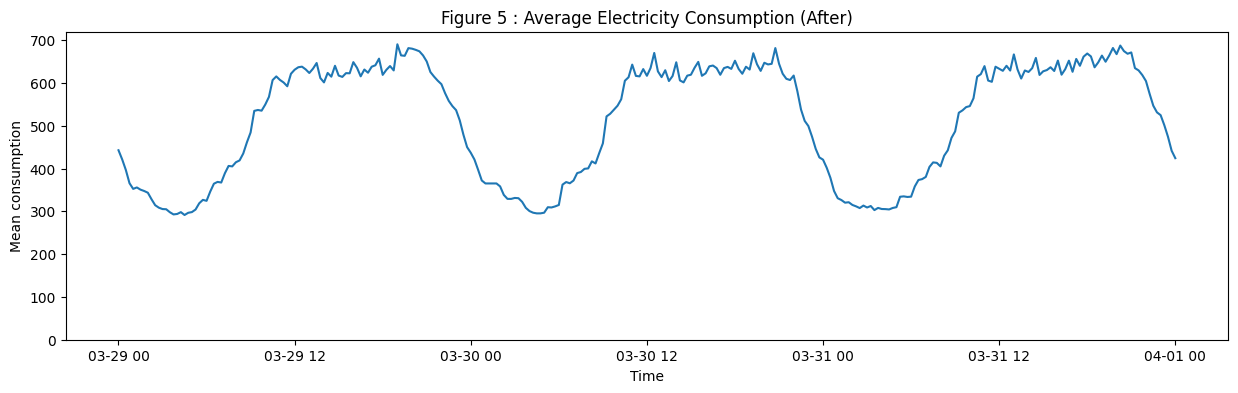

In [17]:
# Display the average consumption at DST After handling the error
#------------------------------------------------------------------
start = "2014-03-29 00:00:00" ; end = "2014-04-01 0:00:00"
mean_consumption = df.mean(axis=1).loc[start:end]
plt.figure(figsize=(15, 4))
plt.plot(mean_consumption.index, mean_consumption)
plt.ylim((0,720))
plt.xlabel("Time")
plt.ylabel("Mean consumption")
plt.title("Figure 5 : Average Electricity Consumption (After)")
plt.show()

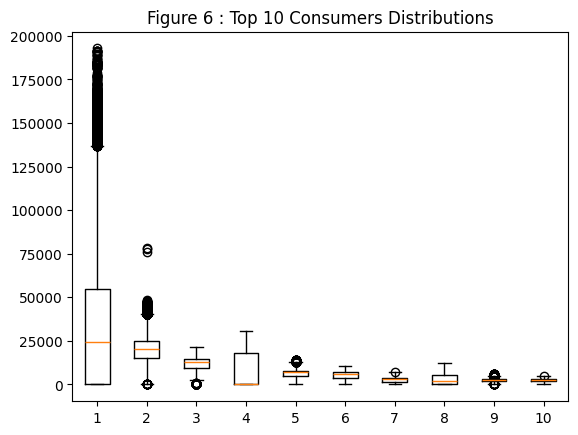

In [18]:
# Box-Plot for the top 10 consumers
#------------------------------------
consumer_mean = df.mean(axis=0)
top_consumers = consumer_mean.nlargest(10).index
plt.boxplot(df[top_consumers])
plt.title("Figure 6 : Top 10 Consumers Distributions")
plt.show()


<hr color=white>

### **PLAN:**
**1. First thing we would do is to split the DataFrame into 370 DataFrame**<br>
**2. So each consumer will be in a separated dataframe to preprocessing and feature engineering**<br>
**3. After feature engineering each consumer (DataFrame), DataFrames will be combined to use it in training the AI Model.**<br>

<hr>

In [19]:
dfs = [df[[column]] for column in df.columns] # split the DataFrame into DataFrames (DataFrame for each consumer)
print(len(dfs)) # number of DataFrames (Number of Consumers)

370


In [20]:
dfs_trimmed = [] # list to hold new DataFrames after trimming (Removing leading zeros)

for data in dfs: # loop all DataFrames
    column = data.columns[0] # Get column name [ MT0_001, MT0_002, MT0_003   ....   MT0_370 ]

    non_zero = data[column].ne(0) # Find Non-zero points
    
    if non_zero.any(): # if the series has at least one non-zero value
        first_valid = non_zero.idxmax() # Get first non-zero index (since all values are `1` the index of the maximum number will be the first one in the series)
        data = data.loc[first_valid:]   # Trim the series
    dfs_trimmed.append(data)

# DataFrames have different length now after trimming it

MT_101    428
dtype: int64
MT_102    684
dtype: int64
MT_103    0
dtype: int64
MT_104    0
dtype: int64


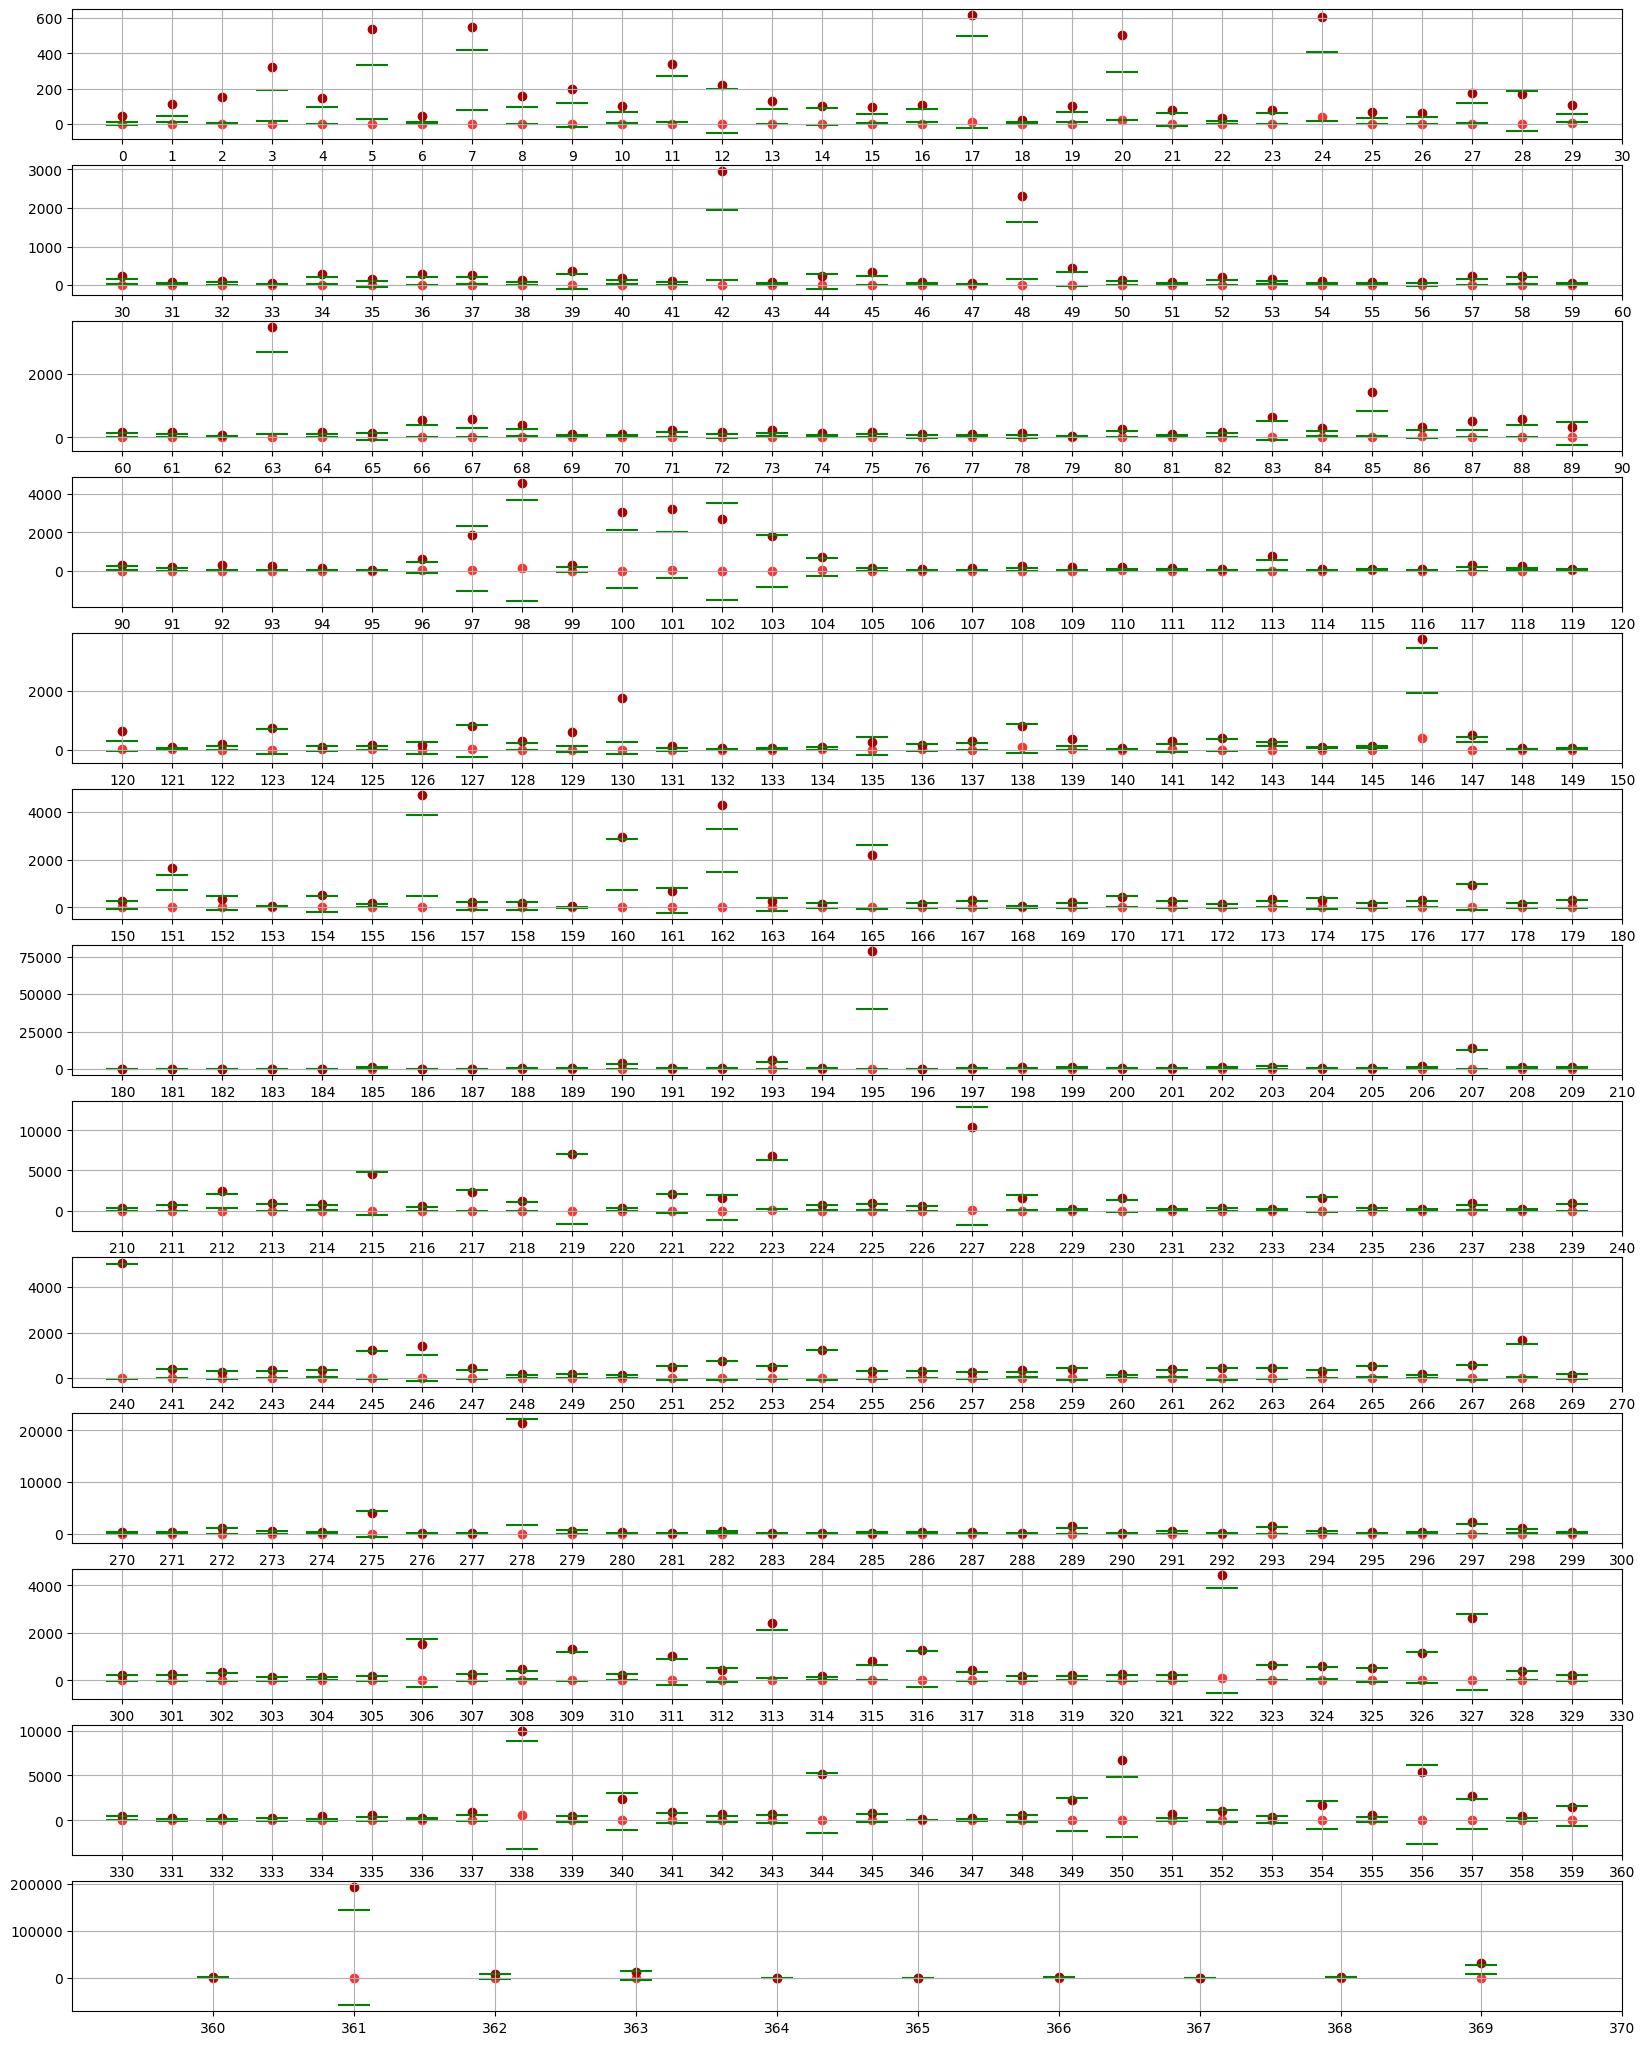

In [21]:

Q1 = pd.Series(data=[ float(_df.quantile(0.25).iloc[0]) for _df in dfs_trimmed])
Q3 = pd.Series(data=[ float(_df.quantile(0.75).iloc[0]) for _df in dfs_trimmed])

IQR = Q3-Q1
min_boundaries = Q1 - IQR*1.5
max_boundaries = Q3 + IQR*1.5


min_values = [_df.min().iloc[0] for _df in dfs_trimmed]
max_values = [_df.max().iloc[0] for _df in dfs_trimmed]


for index , _df in enumerate(dfs_trimmed):
    if index in [100,101,102,103]:
        print(((_df<min_boundaries[index]) | (_df>max_boundaries[index])).sum())
    



start = 0
end = 30
number_of_iter = int(370/end+0.999)

plt.figure(figsize=(20,2*number_of_iter))
for i in range(1,number_of_iter+1):
    plt.subplot(number_of_iter,1,i)
    length = min_values[start:end].__len__()
    plt.scatter(range(start,start+length) , min_values[start:end] , color="#ff3232")
    plt.scatter(range(start,start+length) , max_values[start:end] , color="#a90000")
    plt.scatter(range(start,start+length) , max_boundaries[start:end] , color="green" , s=500 , marker="_")
    plt.scatter(range(start,start+length) , min_boundaries[start:end] , color="green" , s=500 , marker="_")
    
    plt.grid()
    plt.xlim(start-1, start+length )
    plt.xticks(range(start , start+length + 1))
    start +=30
    end +=30

plt.show()




In [22]:
dfs_trimmed[0].head() # Display first DataFrame (Start at `2012`)


,MT_001
DateTime,
2012-01-01 00:15:00,3.807107
2012-01-01 00:30:00,5.076142
2012-01-01 00:45:00,3.807107
2012-01-01 01:00:00,3.807107
2012-01-01 01:15:00,5.076142


10560
55071
55238


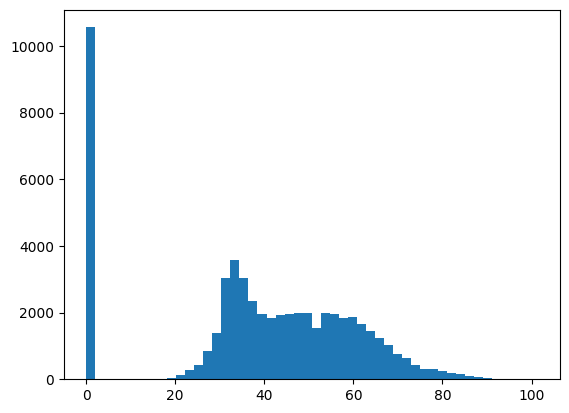

In [23]:
data = dfs_trimmed[14]
print((data==0).sum().sum())
print(data.duplicated().sum())
print(data.__len__())
dfs_trimmed[0]
# Example of an client consumption who start at 2012
#----------------------------------------------------

plt.hist(data[data.columns[0]],bins=50)


plt.show()

<hr>

**Since the forecasting model will operate on an hourly time resolution,**<br>
**each consumer's time series is resampled from 15-minute intervals to 1-hour intervals.**

In [24]:
dfs_hourly = [ consumer.resample('1h').mean()  for consumer in dfs_trimmed ]
dfs_hourly[170].head()

,MT_171
DateTime,
2011-01-01 00:00:00,146.988922
2011-01-01 01:00:00,151.540785
2011-01-01 02:00:00,143.202417
2011-01-01 03:00:00,140.158610
2011-01-01 04:00:00,140.929003


<hr color=white>
<hr color=white>

# $$Feature \space\space Engineering \space\space Part$$


The Target (output) of the AI Model is the forecast of the customer's next hour of consumption.<br>
To help the model to forecast, **The Model will be provided with `168` hours prior to the target time.**<br>

For More Feature Enrichment<br>
The model will be provided with :<br>
* **The month that corresponding to the target time**
* **The day_of_week that corresponding to the target time**
* **The hour_of_day that corresponding to the target time**

**why 168 ?**<br>
`168` hour represent the whole week, and since the same hour in the previous week highly correlated with the target hour<br>
feeding the model with the last `168` hour could reveal the pattern to the model


# **<font color="#ff1919">Warning</font>**

* <font color="#fffb18">The code below will result a huge amont of data that could excees <font color="#ff1919">27 GB</font> located on the Hard Disk</font><br>
* <font color="#fffb18">To Contral the amount of data generated, higher `limit` variable will result bigger amount of data</font>

تم فصل بيانات كل مستهلك في ملف 
CSV مستقل لأن لكل عميل نمط استهلاك فريداً ومختلفاً،
 مما يتيح لنا تدريب نموذج XGBoost
  مخصص لكل مستهلك على حدة والحصول على تقييم دقيق لأدائه. كما أن هذه الطريقة تحمي النظام من استهلاك ذاكرة الجهاز (RAM) 
  في حال تم دمج بيانات 370 مستهلكاً في ملف ضخم واحد، وتضمن تطبيق التقسيم الزمني و (MinMaxScaler) بشكل مستقل ودقيق لكل عميل لمنع تسريب البيانات (Data Leakage).

ملاحظة تم تعديل الlimitليشمل كل المستهلكين

In [25]:


result_folder = r"C:\Users\LEGION 5\Desktop\choch you\results"
try:os.mkdir(result_folder)
except:pass
print("Number of DataFrames : 370")
counter = 0
limit = 370  #  Each DataFrame could result 100 MB of data approximately
verbos = 1  #  ( 1:Print result as it generated ) | () 0:Print only final result )
_limit = limit
number_of_examples = 0
for consumer_df in dfs_hourly: # loop the DataFrames
    counter +=1
    limit -= 1
    
    consumer = consumer_df.columns[0]
    data = consumer_df.copy()
    data = data.rename(columns={consumer: 'target'})      # Set the target time
    lags = pd.concat(
        [data['target'].shift(i) for i in range(1, 169)], # Specify the cilent consumption in the last 168 hour
        axis=1
    )

    lags.columns = [f't-{i}' for i in range(1, 169)]  # Rename the columns to (t-1 , t-2 , ... , t-168)

    data['month'] = data.index.month         # Extract The month that corresponding to the target time
    data['dayofweek'] = data.index.dayofweek # Extract The dayofweek that corresponding to the target time
    data['hour'] = data.index.hour           # Extract The hourofday that corresponding to the target time
    data = pd.concat([data, lags], axis=1)
    
    data = data.dropna()  # delete the null values that coused be the lag (shift)
    # gg = data.iloc[:,4:]
    # print((gg == 0).sum())
    # print(gg.__len__())

    print(f"[{consumer}] Zeros : ",(data == 0).sum())


    number_of_examples += data.shape[0]
    result_path = os.path.join(result_folder , f"{consumer}.csv")
    data.to_csv(result_path , index=False)
    if verbos : print(f"[{counter:03d}/{(_limit if _limit<370 else 370)}] Extract {data.shape[0]} Examples ...... Results saved in '{consumer}.csv'")
    if limit == 0:print("[-] Exiting ....");break
    
print("Final Result :")
print(f"[+] All Results saved in {result_folder}.")
print(f"[+] Complete {counter} DataFrame.")
print(f"[+] The Process results {number_of_examples} Examples, that could be used to train the AI model.")


Number of DataFrames : 370
[MT_001] Zeros :  target         37
month           0
dayofweek    3744
hour         1090
t-1            37
             ... 
t-164          37
t-165          37
t-166          37
t-167          37
t-168          37
Length: 172, dtype: int64
[001/370] Extract 26137 Examples ...... Results saved in 'MT_001.csv'
[MT_002] Zeros :  target          0
month           0
dayofweek    3744
hour         1090
t-1             0
             ... 
t-164           0
t-165           0
t-166           0
t-167           0
t-168           0
Length: 172, dtype: int64
[002/370] Extract 26137 Examples ...... Results saved in 'MT_002.csv'
[MT_003] Zeros :  target        147
month           0
dayofweek    3744
hour         1090
t-1           147
             ... 
t-164         126
t-165         125
t-166         124
t-167         123
t-168         122
Length: 172, dtype: int64
[003/370] Extract 26137 Examples ...... Results saved in 'MT_003.csv'
[MT_004] Zeros :  target          0
m

28


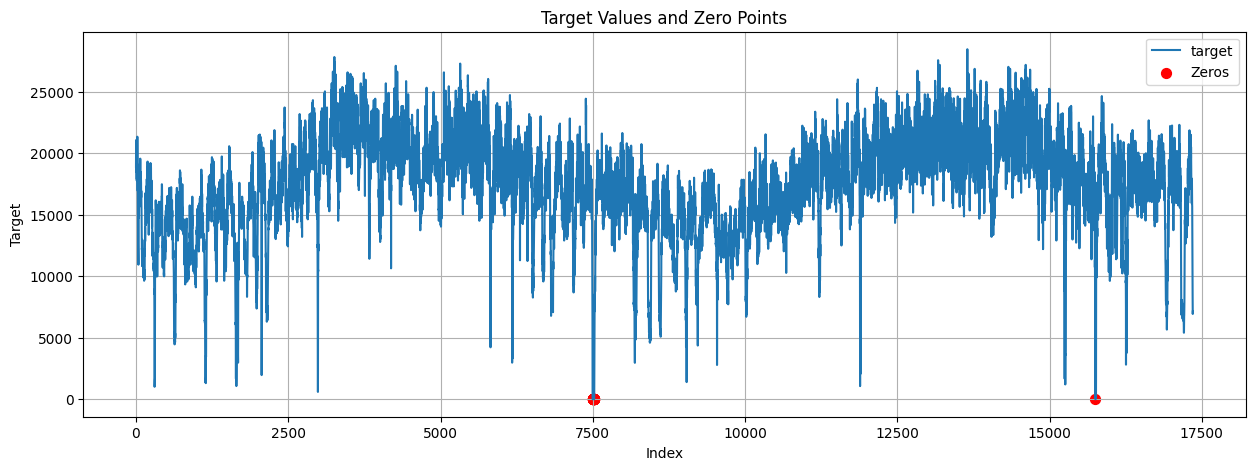

In [58]:
import matplotlib.pyplot as plt

print((data["target"]==0).sum())


plt.figure(figsize=(15, 5))

plt.plot(data.index, data["target"], label="target")

# تحديد أماكن الأصفار
zero_points = data["target"] == 0

plt.scatter(
    data.index[zero_points],
    data["target"][zero_points],
    color="red",
    s=50,
    label="Zeros"
)

plt.xlabel("Index")
plt.ylabel("Target")
plt.title("Target Values and Zero Points")
plt.legend()
plt.grid(True)

plt.show()

In [59]:

# Display an example of the result
#-----------------------------------
data.index = range(len(data))

# data.iloc[24020,:15]
data[data==0]

,target,month,dayofweek,hour,t-1,t-2,t-3,t-4,t-5,t-6,...,t-159,t-160,t-161,t-162,t-163,t-164,t-165,t-166,t-167,t-168
0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17348,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17349,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:


print(data.head())

         target  month  dayofweek  hour           t-1           t-2  \
0  18908.108108      1          1     0  16648.648649  17481.081081   
1  19681.081081      1          1     1  18908.108108  16648.648649   
2  21048.648649      1          1     2  19681.081081  18908.108108   
3  19383.783784      1          1     3  21048.648649  19681.081081   
4  19502.702703      1          1     4  19383.783784  21048.648649   

            t-3           t-4           t-5           t-6  ...        t-159  \
0  17243.243243  17600.000000  19086.486486  19800.000000  ...  6481.081081   
1  17481.081081  17243.243243  17600.000000  19086.486486  ...  7313.513514   
2  16648.648649  17481.081081  17243.243243  17600.000000  ...  6421.621622   
3  18908.108108  16648.648649  17481.081081  17243.243243  ...  6302.702703   
4  19681.081081  18908.108108  16648.648649  17481.081081  ...  6183.783784   

         t-160        t-161        t-162        t-163        t-164  \
0  6897.297297  7254.054054 

لحساب الارتباط بين columns

You should consider upgrading via the 'C:\Users\LEGION 5\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


الأعمدة الموجودة في الملف: Index(['target', 'month', 'dayofweek', 'hour', 't-1', 't-2', 't-3', 't-4',
       't-5', 't-6'],
      dtype='object')


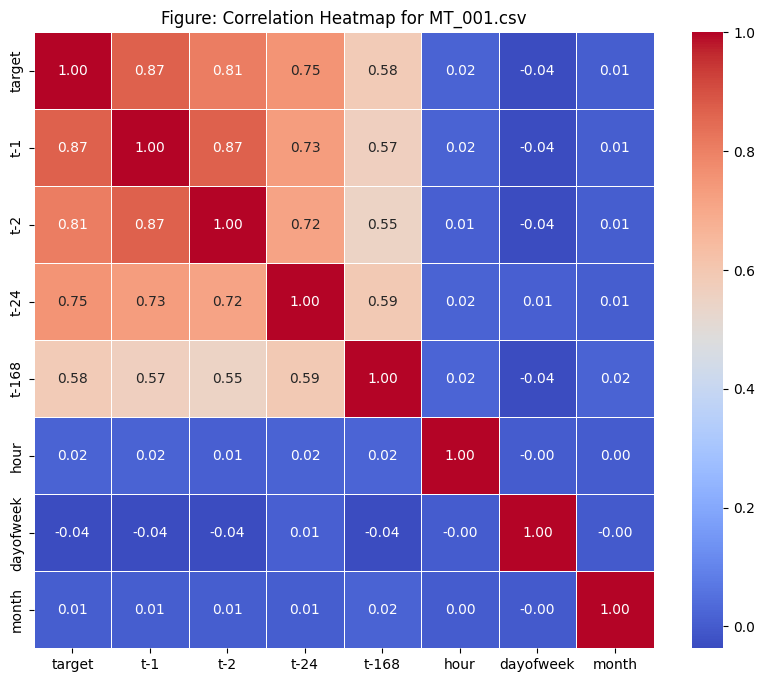

In [ ]:
!pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt
# 1. التأكد من قراءة الملف من مجلد النتائج (حيث توجد البيانات المعالجة والجاهزة)
result_folder = r"C:\Users\LEGION 5\Desktop\choch you\results"
sample_file = "MT_001.csv" 
file_path = os.path.join(result_folder, sample_file)

df = pd.read_csv(file_path)

# 2. طباعة أسماء الأعمدة للتأكد من وجودها
print("الأعمدة الموجودة في الملف:", df.columns[:10])

# 3. حساب مصفوفة الارتباط بأمان
corr_columns = ['target', 't-1', 't-2', 't-24', 't-168', 'hour', 'dayofweek', 'month']
correlation_matrix = df[corr_columns].corr()

# 4. رسم خريطة الحرارة (Correlation Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title(f"Figure: Correlation Heatmap for {sample_file}")
plt.show()

استيراد مكتبات  

In [ ]:

import sys
!{sys.executable} -m pip install scikit-learn# لا تعمل runلهذا السطر لانه انا هاي المكتبة مش نازله عندي على الvs
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import MinMaxScaler


'c:\Users\LEGION' is not recognized as an internal or external command,
operable program or batch file.


تجربة ال modelعلى عينه مستهلك واحد

In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ==========================================
# 1. LOAD DATA: قراءة ملف المستهلك
# ==========================================
# الهدف: قراءة بيانات استهلاك الكهرباء المعالجة (التي تحتوي على الـ Lags والخصائص الزمنية)
result_folder = r"C:\Users\LEGION 5\Desktop\choch you\results"
consumer_file = os.path.join(result_folder, "MT_001.csv") 

df = pd.read_csv(consumer_file)


# ==========================================
# 2. TEMPORAL TRAIN/TEST SPLIT: التقسيم الزمني الصارم
# ==========================================
# الهدف: منع خلط البيانات وضمان عدم رؤية النموذج للمستقبل. 
# نأخذ أول 80% من الزمن للتدريب (Past) وآخر 20% للاختبار (Future).
train_size = int(len(df) * 0.8)
train_data = df.iloc[:train_size].copy()
test_data = df.iloc[train_size:].copy()

print(f"Train size: {len(train_data)} rows | Test size: {len(test_data)} rows")


# ==========================================
# 3. FEATURE SCALING (LEAK-FREE): تطبيع البيانات دون تسريب
# ==========================================
# الهدف: استخدام MinMaxScaler وتطبيق الـ fit حصراً على بيانات التدريب، 
# ثم تطبيق الـ transform على الاختبار لمنع تسريب معلومات المستقبل (Data Leakage).
scaler = MinMaxScaler()

# حساب الحدود وتطبيق التطبيع على بيانات التدريب فقط
train_data['target'] = scaler.fit_transform(train_data[['target']])

# تطبيق مقاييس التدريب على بيانات الاختبار فقط
test_data['target'] = scaler.transform(test_data[['target']])


# ==========================================
# 4. FEATURE & TARGET SEPARATION: فصل الميزات عن الهدف
# ==========================================
# الهدف: تجهيز المصفوفات للتدريب بفصل المتغير المستهدف (target) عن الميزات السابقة (Lags & Time features)
X_train = train_data.drop(columns=['target'])
y_train = train_data['target']

X_test = test_data.drop(columns=['target'])
y_test = test_data['target']


# ==========================================
# 5. MODEL TRAINING: بناء وتدريب نموذج XGBoost
# ==========================================
# الهدف: استخدام خوارزمية XGBoost Regressor للتعلم من الأنماط السابقة وتوقع الاستهلاك
model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

print("[-] Training XGBoost Model...")
model.fit(X_train, y_train)


# ==========================================
# 6. EVALUATION: التنبؤ وحساب مقاييس الأخطاء
# ==========================================
# الهدف: قياس دقة النموذج على بيانات الاختبار باستخدام RMSE و MAE للحكم على أداء التنبؤ
predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)

print("\n--- Evaluation Results ---")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

Train size: 20909 rows | Test size: 5228 rows
[-] Training XGBoost Model...

--- Evaluation Results ---
RMSE: 0.0569
MAE:  0.0279


الmodel المدرب عل جميع المستهلكين

In [3]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. تحديد مسار مجلد النتائج ومجلد لحفظ الرسومات
result_folder = r"C:\Users\LEGION 5\Desktop\choch you\results"
plots_folder = os.path.join(result_folder, "plots")
os.makedirs(plots_folder, exist_ok=True) # إنشاء مجلد للرسومات إذا لم يكن موجوداً

# جلب ملفات المستهلكين فقط
client_files = [f for f in os.listdir(result_folder) if f.endswith('.csv') and not f.startswith('all_')]

print(f"[+] Found {len(client_files)} client files to process and plot.")

evaluation_results = []

# 2. حلقة تكرارية لتدريب وتقييم ورسم النتائج لكل مستهلك
for idx, file_name in enumerate(client_files, 1):
    file_path = os.path.join(result_folder, file_name)
    df = pd.read_csv(file_path)
    
    if 'target' not in df.columns or len(df) < 200:
        continue
        
    client_id = file_name.replace('.csv', '')
    
    # 3. التقسيم الزمني (Train / Test Split) بدون خلط
    train_size = int(len(df) * 0.8)
    train_data = df.iloc[:train_size].copy()
    test_data = df.iloc[train_size:].copy()
    
    # 4. تطبيق الـ Scaler لتجنب تسريب البيانات
    scaler = MinMaxScaler()
    train_data['target'] = scaler.fit_transform(train_data[['target']])
    test_data['target'] = scaler.transform(test_data[['target']])
    
    # 5. فصل الميزات عن الهدف
    X_train = train_data.drop(columns=['target'])
    y_train = train_data['target']
    X_test = test_data.drop(columns=['target'])
    y_test = test_data['target']
    
    # 6. بناء وتدريب نموذج XGBoost
    model = xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    
    # 7. التنبؤ وحساب الأخطاء
    predictions = model.predict(X_test)
    train_predictions = model.predict(X_train)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
    test_rmse = np.sqrt(mean_squared_error(y_test, predictions))
    test_mae = mean_absolute_error(y_test, predictions)
    
    # تخزين النتائج
    evaluation_results.append({
        'Client': file_name,
        'Train_RMSE': train_rmse,
        'Test_RMSE': test_rmse,
        'Test_MAE': test_mae
    })
    
    # 8. رسم المقارنة (أول 150 ساعة فقط) وحفظ الصورة تلقائياً
    plt.figure(figsize=(14, 6))
    plt.plot(y_test.values[:150], label='Actual Load (الاستهلاك الحقيقي)', color='blue', linewidth=2)
    plt.plot(predictions[:150], label='Predicted Load (الاستهلاك المتوقع)', color='red', linestyle='--', linewidth=2)

    plt.title(f"Electricity Load Forecasting vs Actual - {client_id}")
    plt.xlabel("Hours (ساعات الاختبار)")
    plt.ylabel("Normalized Consumption (الاستهلاك المطبع)")
    plt.legend()
    plt.grid(True)
    
    # حفظ الرسم كصورة داخل مجلد الـ plots
    plot_path = os.path.join(plots_folder, f"{client_id}_plot.png")
    plt.savefig(plot_path)
    plt.close() # إغلاق الـ figure لتفريغ الذاكرة العشوائية (RAM)
    
    print(f"[{idx:03d}/{len(client_files)}] Processed & Plot saved for: {client_id}")

# 9. حفظ جدول الملخص النهائي
results_df = pd.DataFrame(evaluation_results)
summary_output_path = os.path.join(result_folder, "all_models_evaluation_summary.csv")
results_df.to_csv(summary_output_path, index=False)

print("\n--- All Models Trained and Plots Generated Successfully! ---")
print(f"[+] Plots are saved in: {plots_folder}")

[+] Found 370 client files to process and plot.
[001/370] Processed & Plot saved for: MT_001
[002/370] Processed & Plot saved for: MT_002
[003/370] Processed & Plot saved for: MT_003
[004/370] Processed & Plot saved for: MT_004
[005/370] Processed & Plot saved for: MT_005
[006/370] Processed & Plot saved for: MT_006
[007/370] Processed & Plot saved for: MT_007
[008/370] Processed & Plot saved for: MT_008
[009/370] Processed & Plot saved for: MT_009
[010/370] Processed & Plot saved for: MT_010
[011/370] Processed & Plot saved for: MT_011
[012/370] Processed & Plot saved for: MT_012
[013/370] Processed & Plot saved for: MT_013
[014/370] Processed & Plot saved for: MT_014
[015/370] Processed & Plot saved for: MT_015
[016/370] Processed & Plot saved for: MT_016
[017/370] Processed & Plot saved for: MT_017
[018/370] Processed & Plot saved for: MT_018
[019/370] Processed & Plot saved for: MT_019
[020/370] Processed & Plot saved for: MT_020
[021/370] Processed & Plot saved for: MT_021
[022/37